# EVA-02: A Visual Representation Powerhouse Reconstructed from EVA

**Paper:** Y. Fang, W. Sun, X. Wang, L. Wu, J. Wang, D. Cao, X. Chang, and Y. Wang, "EVA-02: A Visual Representation Powerhouse Reconstructed from EVA," *arXiv preprint arXiv:2303.11331*, 2023. [arXiv:2303.11331](https://arxiv.org/abs/2303.11331)

**Summary:** EVA-02 reconstructs ViT using three targeted improvements — 2D Rotary Position Embeddings (RoPE), SwiGLU feed-forward networks, and Sub-Layer Normalization for Q and K — achieving state-of-the-art visual representations through CLIP-aligned pre-training.

> 📄 **Paper:** Fang et al. (2024). EVA-02: A Visual Representation for Neon Genesis. Image and Vision Computing 2024.
> 🔗 **Link:** <https://arxiv.org/abs/2303.11331>
> 🧩 **Implementation:** `hale_core/nn/vision/vit/eva.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> PE["PatchEmbed 14×14 or 16×16"]:::stage --> ENC["L × EVA-02 block"]:::stage --> NORM["LN"]:::block --> OUT
  subgraph TB["EVA-02 block"]
    direction LR
    X["x"] --> LN1["LN"]:::block --> ATT["MSA with 2D RoPE on q, k"]:::block --> A1(("+"))
    X --> A1 --> LN2["LN"]:::block --> SW["SwiGLU MLP (+ sub-LN)"]:::block --> A2(("+"))
    A1 --> A2
  end
  ENC -.-> TB
  MIM["MIM pre-training: regress EVA-CLIP features of masked patches"]:::block -.-> ENC
  OUT["BackboneOutput<br/>pooled_output (B, D)<br/>patch_tokens (B, N, D)<br/>feature_maps [(B, D, H/p, W/p)]"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

## Architecture Overview

```
Input Image [B, 3, H, W]
        │
        ▼  PatchEmbed (Conv2d, patch_size=16 or 14)
Patches [B, N, D]  — NO positional embedding added here!
        │            Positions are encoded in Q,K via RoPE inside each block
        ▼  ┌────────────────────────────────────────────────────────────────┐
           │  EVABlock × depth                                              │
           │  ┌──────────────────────────────────────────────────────────┐  │
           │  │  x = x + EVAAttention(LN(x),  rope_cos, rope_sin)       │  │
           │  │  x = x + SwiGLUFFN(LN(x))                               │  │
           │  │                                                          │  │
           │  │  EVAAttention internals:                                 │  │
           │  │    Q,K,V  = in_proj(x)                                   │  │
           │  │    Q = q_norm(Q)  ← Sub-LN on Q                         │  │
           │  │    K = k_norm(K)  ← Sub-LN on K                         │  │
           │  │    Q,K = apply_rope(Q,K, rope_cos, rope_sin)            │  │
           │  │    Attn = softmax(QKᵀ/√d) · V                           │  │
           │  │                                                          │  │
           │  │  SwiGLUFFN internals:                                    │  │
           │  │    gate  = SiLU(W₁·x)  ← gated branch                   │  │
           │  │    value = W₂·x         ← value branch                  │  │
           │  │    out   = W₃·(gate ⊙ value)                            │  │
           │  │    hidden = ⌈8/3 × D / 256⌉ × 256  (≈2.67D)            │  │
           │  └──────────────────────────────────────────────────────────┘  │
           └────────────────────────────────────────────────────────────────┘
        │
        ▼  Final LayerNorm
        │
        ├──► pooled_output = mean(x, dim=1)   [B, D]  (mean pool, NO CLS token)
        └──► patch_tokens  = x                [B, N, D]
             feature_maps  = reshape → [B, D, H/p, W/p]
```

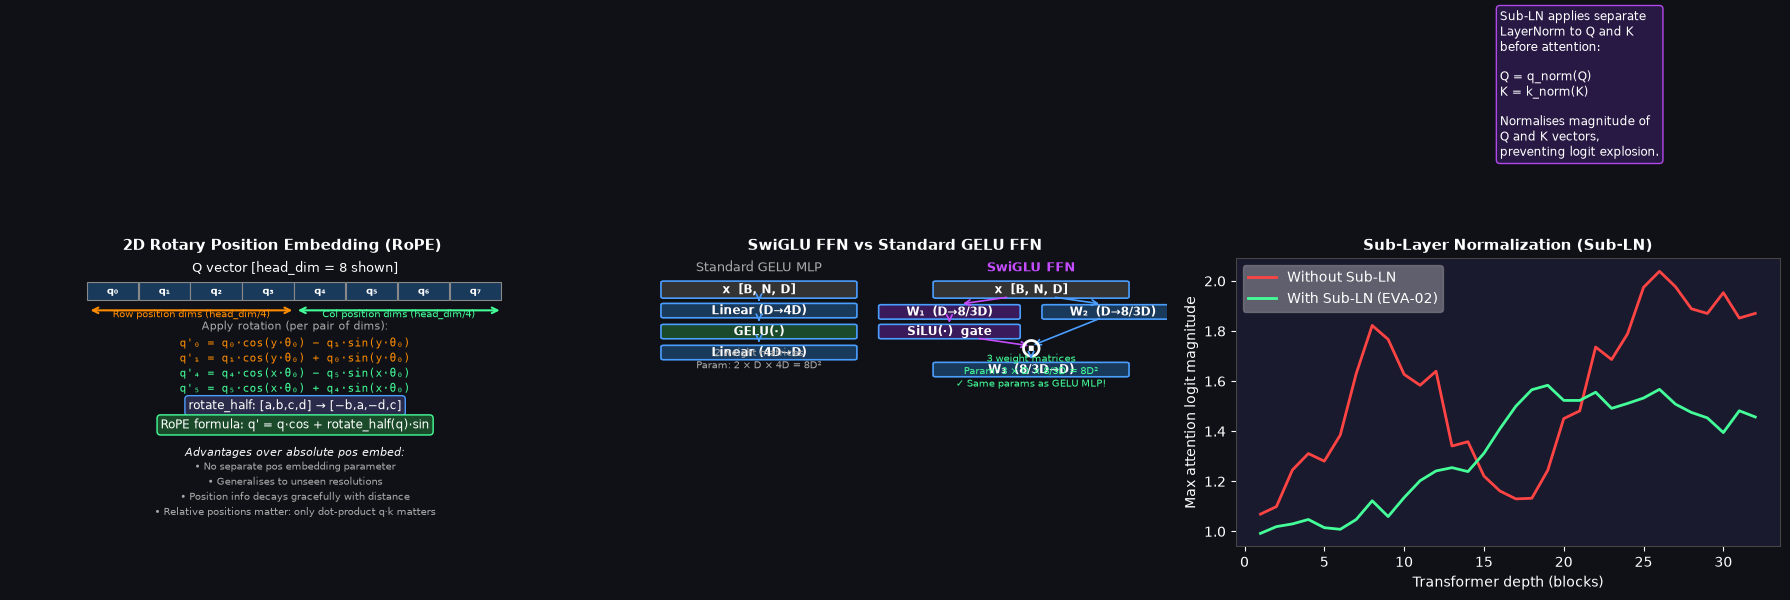

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
fig.patch.set_facecolor('#0f1117')

# ── Panel 1: 2D RoPE Diagram ─────────────────────────────────────────────────
ax1 = axes[0]
ax1.set_facecolor('#0f1117')
ax1.set_xlim(-0.5, 10)
ax1.set_ylim(-0.5, 10)
ax1.axis('off')
ax1.set_title('2D Rotary Position Embedding (RoPE)', color='white', fontsize=11, fontweight='bold')

# Draw a query vector and show it being rotated
def vec_box(ax, x, y, w, h, items, color='#1a3a5c'):
    for i, item in enumerate(items):
        xi = x + i * w / len(items)
        p = FancyBboxPatch((xi, y), w/len(items)-0.05, h,
                            boxstyle='square,pad=0.02', facecolor=color,
                            edgecolor='#888', linewidth=0.8)
        ax.add_patch(p)
        ax.text(xi + w/len(items)/2 - 0.025, y + h/2, item, ha='center',
                va='center', color='white', fontsize=7.5, fontweight='bold')

# Original Q dim: [q₀,q₁ | q₂,q₃ | q₄,q₅ | q₆,q₇]
ax1.text(5, 9.5, 'Q vector [head_dim = 8 shown]', ha='center', color='white', fontsize=9)
items_q = ['q₀','q₁','q₂','q₃','q₄','q₅','q₆','q₇']
vec_box(ax1, 1, 8.5, 8, 0.6, items_q, '#1a3a5c')

# Brackets: row dims vs col dims
ax1.annotate('', xy=(1, 8.1), xytext=(5, 8.1),
             arrowprops=dict(arrowstyle='<->', color='#ff8c00', lw=1.5))
ax1.text(3, 7.85, 'Row position dims (head_dim/4)', ha='center', color='#ff8c00', fontsize=7.5)
ax1.annotate('', xy=(5, 8.1), xytext=(9, 8.1),
             arrowprops=dict(arrowstyle='<->', color='#44ff99', lw=1.5))
ax1.text(7, 7.85, 'Col position dims (head_dim/4)', ha='center', color='#44ff99', fontsize=7.5)

# Rotation formula
ax1.text(5, 7.4, 'Apply rotation (per pair of dims):', ha='center', color='#aaa', fontsize=8)

formulas = [
    ("q'₀ = q₀·cos(y·θ₀) − q₁·sin(y·θ₀)", '#ff8c00'),
    ("q'₁ = q₁·cos(y·θ₀) + q₀·sin(y·θ₀)", '#ff8c00'),
    ("q'₄ = q₄·cos(x·θ₀) − q₅·sin(x·θ₀)", '#44ff99'),
    ("q'₅ = q₅·cos(x·θ₀) + q₄·sin(x·θ₀)", '#44ff99'),
]
for i, (f, c) in enumerate(formulas):
    ax1.text(5, 6.9 - i*0.55, f, ha='center', va='center', color=c, fontsize=8, family='monospace')

# rotate_half explanation
ax1.text(5, 4.5, 'rotate_half: [a,b,c,d] → [−b,a,−d,c]', ha='center', color='white',
         fontsize=8.5, bbox=dict(boxstyle='round', facecolor='#2a2a4a', edgecolor='#4a9eff'))
ax1.text(5, 3.8, 'RoPE formula: q\' = q·cos + rotate_half(q)·sin',
         ha='center', color='white', fontsize=8.5,
         bbox=dict(boxstyle='round', facecolor='#1a4a2a', edgecolor='#44ff99'))

# Advantage
ax1.text(5, 2.8, 'Advantages over absolute pos embed:', ha='center', color='white', fontsize=8, style='italic')
advantages = [
    '• No separate pos embedding parameter',
    '• Generalises to unseen resolutions',
    '• Position info decays gracefully with distance',
    '• Relative positions matter: only dot-product q·k matters',
]
for i, a in enumerate(advantages):
    ax1.text(5, 2.3 - i*0.55, a, ha='center', color='#aaa', fontsize=7.5)

# ── Panel 2: SwiGLU FFN diagram ───────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#0f1117')
ax2.set_xlim(0, 10)
ax2.set_ylim(0, 11)
ax2.axis('off')
ax2.set_title('SwiGLU FFN vs Standard GELU FFN', color='white', fontsize=11, fontweight='bold')

def box2(ax, x, y, w, h, txt, sub='', fc='#1a3a5c'):
    p = FancyBboxPatch((x-w/2, y-h/2), w, h, boxstyle='round,pad=0.05',
                        facecolor=fc, edgecolor='#4a9eff', linewidth=1.2)
    ax.add_patch(p)
    ax.text(x, y + (0.1 if sub else 0), txt, ha='center', va='center',
            color='white', fontsize=8.5, fontweight='bold')
    if sub:
        ax.text(x, y-0.28, sub, ha='center', va='center', color='#aaa', fontsize=7)

# Standard GELU MLP (left side)
ax2.text(2.5, 10.5, 'Standard GELU MLP', ha='center', color='#aaa', fontsize=9)
box2(ax2, 2.5, 9.8, 3.5, 0.55, 'x  [B, N, D]', '', '#333')
ax2.annotate('', xy=(2.5, 9.25), xytext=(2.5, 9.52),
             arrowprops=dict(arrowstyle='->', color='#4a9eff', lw=1.2))
box2(ax2, 2.5, 9.0, 3.5, 0.45, 'Linear (D→4D)', '', '#1a3a5c')
ax2.annotate('', xy=(2.5, 8.48), xytext=(2.5, 8.78),
             arrowprops=dict(arrowstyle='->', color='#4a9eff', lw=1.2))
box2(ax2, 2.5, 8.2, 3.5, 0.45, 'GELU(·)', '', '#1a4a2a')
ax2.annotate('', xy=(2.5, 7.68), xytext=(2.5, 7.98),
             arrowprops=dict(arrowstyle='->', color='#4a9eff', lw=1.2))
box2(ax2, 2.5, 7.4, 3.5, 0.45, 'Linear (4D→D)', '', '#1a3a5c')
ax2.text(2.5, 6.8, '2 weight matrices\nParam: 2 × D × 4D = 8D²', ha='center',
         color='#aaa', fontsize=7.5)

# SwiGLU (right side)
ax2.text(7.5, 10.5, 'SwiGLU FFN', ha='center', color='#c44dff', fontsize=9, fontweight='bold')
box2(ax2, 7.5, 9.8, 3.5, 0.55, 'x  [B, N, D]', '', '#333')
# Two parallel branches
ax2.annotate('', xy=(6.2, 9.25), xytext=(7.1, 9.52),
             arrowprops=dict(arrowstyle='->', color='#c44dff', lw=1.2))
ax2.annotate('', xy=(8.8, 9.25), xytext=(7.9, 9.52),
             arrowprops=dict(arrowstyle='->', color='#4a9eff', lw=1.2))
box2(ax2, 6.0, 8.95, 2.5, 0.45, 'W₁  (D→8/3D)', '', '#3a1a5a')
box2(ax2, 9.0, 8.95, 2.5, 0.45, 'W₂  (D→8/3D)', '', '#1a3a5c')
ax2.annotate('', xy=(6.0, 8.45), xytext=(6.0, 8.73),
             arrowprops=dict(arrowstyle='->', color='#c44dff', lw=1.2))
box2(ax2, 6.0, 8.2, 2.5, 0.45, 'SiLU(·)  gate', '', '#3a1a5a')
# Multiply
ax2.annotate('', xy=(7.5, 7.65), xytext=(6.5, 7.95),
             arrowprops=dict(arrowstyle='->', color='#c44dff', lw=1.2))
ax2.annotate('', xy=(7.5, 7.65), xytext=(8.8, 8.73),
             arrowprops=dict(arrowstyle='->', color='#4a9eff', lw=1.2))
ax2.text(7.5, 7.5, '⊙', ha='center', va='center', color='white', fontsize=20, fontweight='bold')
ax2.annotate('', xy=(7.5, 7.05), xytext=(7.5, 7.35),
             arrowprops=dict(arrowstyle='->', color='#4a9eff', lw=1.2))
box2(ax2, 7.5, 6.75, 3.5, 0.45, 'W₃  (8/3D→D)', '', '#1a3a5c')
ax2.text(7.5, 6.1, '3 weight matrices\nParam: 3 × D × 8/3D = 8D²\n✓ Same params as GELU MLP!',
         ha='center', color='#44ff99', fontsize=7.5)

# ── Panel 3: Sub-LN explanation ───────────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor('#0f1117')
ax3.set_title('Sub-Layer Normalization (Sub-LN)', color='white', fontsize=11, fontweight='bold')

# Show logit explosion with and without Sub-LN
depths = np.arange(1, 33)
rng = np.random.default_rng(0)
logits_no_subnorm = 1.0 + np.cumsum(rng.normal(0, 0.15, 32) + 0.05)  # growing
logits_subnorm    = np.clip(1.0 + np.cumsum(rng.normal(0, 0.05, 32)), None, 3.0)

ax3.set_facecolor('#1a1a2e')
ax3.plot(depths, logits_no_subnorm, color='#ff4444', linewidth=2, label='Without Sub-LN')
ax3.plot(depths, logits_subnorm,    color='#44ff99', linewidth=2, label='With Sub-LN (EVA-02)')
ax3.set_xlabel('Transformer depth (blocks)', color='white')
ax3.set_ylabel('Max attention logit magnitude', color='white')
ax3.tick_params(colors='white')
ax3.legend(framealpha=0.3, labelcolor='white')
for sp in ax3.spines.values():
    sp.set_edgecolor('#444')

ax3.text(16, 2.5,
         'Sub-LN applies separate\nLayerNorm to Q and K\nbefore attention:\n\n'
         'Q = q_norm(Q)\nK = k_norm(K)\n\nNormalises magnitude of\nQ and K vectors,\n'
         'preventing logit explosion.',
         color='white', fontsize=8.5,
         bbox=dict(boxstyle='round', facecolor='#2a1a4a', edgecolor='#c44dff', alpha=0.9))

plt.tight_layout()

plt.show()

## 3. Key ideas

## Key Innovations

### 1. 2D Rotary Position Embedding (RoPE)

Standard ViT adds learned absolute positional embeddings to token features before the first block. RoPE instead **encodes position into the rotation of Q and K vectors** inside each attention block.

For a 1D sequence at position $m$, RoPE rotates each consecutive pair $(x_{2i}, x_{2i+1})$:
$$\begin{pmatrix} x'_{2i} \\ x'_{2i+1} \end{pmatrix} = \begin{pmatrix} \cos(m\theta_i) & -\sin(m\theta_i) \\ \sin(m\theta_i) & \cos(m\theta_i) \end{pmatrix} \begin{pmatrix} x_{2i} \\ x_{2i+1} \end{pmatrix}$$

where $\theta_i = 1/10000^{2i/d}$ (same as Transformer sinusoidal frequencies).

For 2D images, EVA-02 uses:
- The **first half** of head dimensions → row-position RoPE (using $y$-coordinate)
- The **second half** of head dimensions → column-position RoPE (using $x$-coordinate)

**Key property:** RoPE is applied to Q and K only. After rotation,
$$q_m^\top k_n = f(q, m)^\top f(k, n)$$
only depends on the **relative** position $(m - n)$, not absolute positions. This means RoPE implicitly computes relative position attention without a separate relative position bias table.

### 2. SwiGLU Feed-Forward Network

Standard ViT MLP: $\text{MLP}(x) = W_2 \cdot \text{GELU}(W_1 x)$ — 2 weight matrices, hidden dim $= 4D$

SwiGLU (Shazeer, 2020):
$$\text{SwiGLU}(x) = W_3 \cdot \bigl(\text{SiLU}(W_1 x) \odot W_2 x\bigr)$$

- 3 weight matrices instead of 2
- Hidden dim scaled to $\lceil 8D/3 / 256 \rceil \times 256 \approx 2.67D$
- Total params: $3 \times D \times \frac{8D}{3} = 8D^2$ — same as GELU MLP ($2 \times D \times 4D = 8D^2$) ✓
- The gating mechanism ($\text{SiLU}(W_1 x) \odot W_2 x$) provides input-dependent selection, empirically outperforming non-gated activations.

### 3. Sub-Layer Normalization (Sub-LN)

Applies separate `LayerNorm` to Q and K **before** computing attention:
```
Q, K, V = in_proj(x)
Q = q_norm(Q)    # LayerNorm per head
K = k_norm(K)    # LayerNorm per head
Attn = softmax(Q·Kᵀ / √d) · V
```

Without Sub-LN, at large scale (large $D$, many heads), Q and K vectors can develop large magnitudes that saturate the softmax (all attention on one token). Sub-LN normalises their magnitude independently of the pre-block LayerNorm.

### 4. No CLS Token — Mean Pooling

EVA-02 uses mean pooling over all patch tokens rather than a special CLS token:
$$z = \frac{1}{N} \sum_{i=1}^{N} x_i$$

This makes all patches equal contributors to the global descriptor and removes the special-token asymmetry.

## Module Walkthrough

### 2D RoPE — Pre-computation
```python
def _build_rope_freqs(grid_size, head_dim, base=10000.0):
    half = head_dim // 4  # row: head_dim/4 dims, col: head_dim/4 dims
    theta = 1.0 / (base ** (arange(0, half) / half))  # frequency bands
    # Grid (row, col) positions:
    py = row_positions.reshape(-1)  # [N]
    px = col_positions.reshape(-1)  # [N]
    ang_y = py[:, None] * theta[None, :]    # [N, half]
    ang_x = px[:, None] * theta[None, :]    # [N, half]
    ang = cat([ang_y, ang_x], dim=1)        # [N, head_dim/2]
    ang = ang.repeat_interleave(2, dim=1)   # [N, head_dim]
    return ang.cos(), ang.sin()             # both [N, head_dim]
```

### _apply_rope — Rotation of Q and K
```python
def _rotate_half(x):
    # [a, b, c, d] → [−b, a, −d, c]
    x1, x2 = x[..., ::2], x[..., 1::2]   # split even/odd
    return stack([-x2, x1], dim=-1).flatten(-2)

def _apply_rope(q, k, cos, sin):
    cos = cos.unsqueeze(0).unsqueeze(0)    # [1, 1, N, d]
    sin = sin.unsqueeze(0).unsqueeze(0)
    q_rot = q * cos + _rotate_half(q) * sin
    k_rot = k * cos + _rotate_half(k) * sin
    return q_rot, k_rot
```

### SwiGLUFFN
```python
class SwiGLUFFN(nn.Module):
    def __init__(self, dim, mlp_ratio=4.0):
        hidden = ceil(dim * mlp_ratio * 2/3 / 256) * 256  # ≈ 8/3 × dim
        self.w1 = nn.Linear(dim, hidden, bias=False)  # gate
        self.w2 = nn.Linear(dim, hidden, bias=False)  # value
        self.w3 = nn.Linear(hidden, dim, bias=False)  # project back

    def forward(self, x):
        gate  = F.silu(self.w1(x))     # SiLU activation = x·σ(x)
        value = self.w2(x)
        return self.w3(gate * value)   # element-wise gate
```

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/vit/eva.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>vit/eva.py</code></summary>

```text
EVA-02 Vision Transformer Backbone
=====================================

Paper: "EVA-02: A Visual Representation Powerhouse Reconstructed from EVA"
       (Fang et al., 2023) — https://arxiv.org/abs/2303.11331

Architecture Overview
---------------------
EVA-02 introduces three key modifications over plain ViT that together achieve
state-of-the-art visual representations:

1. Rotary Position Embedding (2D RoPE)
   Instead of learned absolute positional embeddings added to all tokens, RoPE
   encodes positions by rotating Q and K vectors with position-dependent angles.

   For a 1D sequence, RoPE rotates consecutive pairs (x_{2i}, x_{2i+1}) by θ:
       x' = x·cos(θ) + rotate_half(x)·sin(θ)
   where rotate_half swaps pairs with a sign flip: [a, b, c, d] → [-b, a, -d, c].

   For 2D images, EVA-02 uses separate RoPE for rows and columns:
       - Each head's d/2 dimensions are split into d/4 row + d/4 col dims
       - Row dims rotate by position_y * θ_i, col dims by position_x * θ_i
   This generalises to arbitrary resolutions without interpolation artefacts,
   unlike absolute learned positional embeddings.

2. SwiGLU FFN
   Standard ViT uses GELU(Linear(x)) as the activation gate.  SwiGLU uses:
       SwiGLU(x) = SiLU(W₁x) ⊙ W₂x   (element-wise gate)
   This is a gated linear unit (GLU) variant shown to outperform GELU MLPs at
   the same parameter count (Noam Shazeer, 2020: "GLU Variants Improve Transformer").
   The intermediate dim is scaled by 2/3 × 4 = 8/3 ≈ 2.667× to keep parameter
   count equal to a standard 4× MLP (two matrices instead of one gate).

3. Sub-Layer Normalization (Sub-LN) for Q and K
   Applying LayerNorm to Q and K before computing attention stabilises training
   by preventing attention logit explosion at large scale (large dim, many heads).
   This is independent from the pre-norm applied to the full token sequence.

Output:
   EVA-02 uses mean-pooling over all patch tokens (no CLS token in EVA-02 style)
   as the global pooled_output.

Variants registered
-------------------
  eva_02_small — 384-dim, 6 heads,  12 layers, patch=16
  eva_02_base  — 768-dim, 12 heads, 12 layers, patch=16
  eva_02_large — 1024-dim, 16 heads, 24 layers, patch=14
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### Shared building blocks from `vit/vit.py` used by this family: `PatchEmbed`, `_trunc_normal_`

In [5]:
def _trunc_normal_(tensor: torch.Tensor, std: float = 0.02) -> torch.Tensor:
    """Truncated normal init at ±2σ — standard for ViT weight init."""
    with torch.no_grad():
        # Box–Muller via normal + clamp, then rescale to correct distribution
        nn.init.trunc_normal_(tensor, mean=0.0, std=std, a=-2 * std, b=2 * std)
    return tensor


class PatchEmbed(nn.Module):
    """Convert an image into non-overlapping patch embeddings.

    Uses a single Conv2d with kernel_size=stride=patch_size, which is
    mathematically equivalent to splitting the image into patches and applying
    a shared linear projection to each, but is faster due to BLAS layout.

    Args:
        img_size:   Assumed square input size (used to pre-compute N_patches).
        patch_size: Side length of each square patch (e.g. 16 or 14).
        in_chans:   Input channels (3 for RGB).
        embed_dim:  Projected dimension D.
    """

    def __init__(
        self,
        img_size: int = 224,
        patch_size: int = 16,
        in_chans: int = 3,
        embed_dim: int = 768,
    ) -> None:
        super().__init__()
        self.img_size = img_size
        self.patch_size = patch_size
        self.grid_size = img_size // patch_size          # e.g. 14 for 224/16
        self.num_patches = self.grid_size ** 2

        # A single strided convolution performs the patch extraction + linear projection
        self.proj = nn.Conv2d(in_chans, embed_dim, kernel_size=patch_size, stride=patch_size)
        _trunc_normal_(self.proj.weight)
        nn.init.zeros_(self.proj.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, C, H, W] → [B, D, H/p, W/p] → [B, N, D]
        x = self.proj(x)                                 # [B, D, G, G]
        x = x.flatten(2).transpose(1, 2)                # [B, N, D]
        return x

### 4.2 `vit/eva.py`, definition by definition

In [6]:
def _build_rope_freqs(
    grid_size: int,
    head_dim: int,
    base: float = 10000.0,
) -> tuple[torch.Tensor, torch.Tensor]:
    """Pre-compute RoPE sin/cos frequencies for a 2D grid.

    Each head has `head_dim` dimensions.  We use head_dim/2 for row positions
    and head_dim/2 for column positions.

    Returns:
        cos_freq: [N, head_dim]  (N = grid_size²)
        sin_freq: [N, head_dim]
    """
    # Frequency bands — one per pair of dimensions
    half = head_dim // 4                             # row uses half, col uses half
    theta = 1.0 / (base ** (torch.arange(0, half, dtype=torch.float32) / half))

    # Grid positions
    gy = torch.arange(grid_size, dtype=torch.float32)
    gx = torch.arange(grid_size, dtype=torch.float32)
    # Outer product → N positions
    py = gy.unsqueeze(1).expand(grid_size, grid_size).reshape(-1)  # [N]
    px = gx.unsqueeze(0).expand(grid_size, grid_size).reshape(-1)  # [N]

    # Angles per position per frequency
    ang_y = py.unsqueeze(1) * theta.unsqueeze(0)    # [N, half]
    ang_x = px.unsqueeze(1) * theta.unsqueeze(0)    # [N, half]

    # Concat row and col angles → [N, head_dim/2]
    ang = torch.cat([ang_y, ang_x], dim=1)          # [N, head_dim/2]

    # Duplicate so each pair gets the same angle: [N, head_dim]
    # Pattern: [θ₀, θ₀, θ₁, θ₁, ...] → cos/sin applied to (x₀, x₁) pair
    ang = ang.repeat_interleave(2, dim=1)

    return ang.cos(), ang.sin()

In [7]:
def _rotate_half(x: torch.Tensor) -> torch.Tensor:
    """Rotate pairs of consecutive dimensions: [a, b, c, d] → [-b, a, -d, c]."""
    x1, x2 = x[..., ::2], x[..., 1::2]             # split even/odd dims
    return torch.stack([-x2, x1], dim=-1).flatten(-2)

In [8]:
def _apply_rope(
    q: torch.Tensor,
    k: torch.Tensor,
    cos: torch.Tensor,
    sin: torch.Tensor,
) -> tuple[torch.Tensor, torch.Tensor]:
    """Apply RoPE rotation to Q and K tensors.

    Args:
        q, k:    [B, H, N, d]
        cos, sin: [N, d]  (pre-computed for the sequence length N)

    Returns:
        q', k' with RoPE applied — same shape.
    """
    # Broadcast cos/sin over batch and head dimensions
    cos = cos.unsqueeze(0).unsqueeze(0)              # [1, 1, N, d]
    sin = sin.unsqueeze(0).unsqueeze(0)

    q_rot = q * cos + _rotate_half(q) * sin
    k_rot = k * cos + _rotate_half(k) * sin
    return q_rot, k_rot

**`SwiGLUFFN`** - SwiGLU gated feed-forward network.

In [9]:
class SwiGLUFFN(nn.Module):
    """SwiGLU gated feed-forward network.

    Computes:  SiLU(W₁·x) ⊙ W₂·x → W₃

    The intermediate dim is 8/3 × dim (not 4×) so that the total parameter
    count matches a standard 4× GELU MLP (two projections instead of one).

    Reference: "GLU Variants Improve Transformer" (Shazeer, 2020)
    """

    def __init__(self, dim: int, mlp_ratio: float = 4.0, drop: float = 0.0) -> None:
        super().__init__()
        # Scale hidden dim by 2/3 to keep total params equal to GELU MLP at same ratio
        hidden = int(dim * mlp_ratio * 2 / 3)
        # Make divisible by 256 for efficient GEMM
        hidden = (hidden + 255) // 256 * 256

        self.w1 = nn.Linear(dim, hidden, bias=False)   # gate branch (SiLU)
        self.w2 = nn.Linear(dim, hidden, bias=False)   # value branch
        self.w3 = nn.Linear(hidden, dim, bias=False)   # output projection
        self.drop = nn.Dropout(drop)

        _trunc_normal_(self.w1.weight)
        _trunc_normal_(self.w2.weight)
        _trunc_normal_(self.w3.weight)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # SiLU gate applied element-wise to the value branch
        gate = F.silu(self.w1(x))
        value = self.w2(x)
        return self.drop(self.w3(gate * value))

**`EVAAttention`** - Multi-head self-attention with RoPE and per-QK LayerNorm.

In [10]:
class EVAAttention(nn.Module):
    """Multi-head self-attention with RoPE and per-QK LayerNorm.

    Sub-LN: Separate LayerNorm on Q and K before computing attention.
    This prevents attention logit explosion observed in very large models.

    RoPE: The pre-computed cos/sin buffers must be passed from the backbone
    (they depend on the image resolution, which is fixed at __init__ time).

    Args:
        dim:       Token dimension D.
        num_heads: Number of attention heads H.
        attn_drop: Attention weight dropout.
        proj_drop: Output projection dropout.
    """

    def __init__(
        self,
        dim: int,
        num_heads: int = 8,
        attn_drop: float = 0.0,
        proj_drop: float = 0.0,
    ) -> None:
        super().__init__()
        assert dim % num_heads == 0
        self.num_heads = num_heads
        self.head_dim = dim // num_heads
        self.scale = self.head_dim ** -0.5
        self.attn_drop_p = attn_drop

        self.in_proj = nn.Linear(dim, dim * 3, bias=True)
        self.out_proj = nn.Linear(dim, dim, bias=True)
        self.proj_drop = nn.Dropout(proj_drop)

        # Sub-LN: LayerNorm on Q and K to stabilise deep network training
        self.q_norm = nn.LayerNorm(self.head_dim)
        self.k_norm = nn.LayerNorm(self.head_dim)

        _trunc_normal_(self.in_proj.weight)
        _trunc_normal_(self.out_proj.weight)

    def forward(
        self,
        x: torch.Tensor,
        rope_cos: torch.Tensor,
        rope_sin: torch.Tensor,
        return_attn: bool = False,
    ) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
        B, N, D = x.shape
        H = self.num_heads

        qkv = self.in_proj(x).reshape(B, N, 3, H, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv.unbind(0)                          # each [B, H, N, d]

        # Sub-LN on Q and K (per-head, over head_dim axis)
        q = self.q_norm(q)
        k = self.k_norm(k)

        # Apply 2D RoPE to Q and K — positions come from the spatial grid
        q, k = _apply_rope(q, k, rope_cos.to(q.dtype), rope_sin.to(k.dtype))

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = F.softmax(attn, dim=-1)
        if self.training and self.attn_drop_p > 0:
            attn = F.dropout(attn, p=self.attn_drop_p)
        attn_weights = attn if return_attn else None

        x = (attn @ v).transpose(1, 2).reshape(B, N, D)
        return self.proj_drop(self.out_proj(x)), attn_weights

**`EVABlock`** - EVA-02 transformer block: pre-norm, RoPE attention, SwiGLU FFN.

In [11]:
class EVABlock(nn.Module):
    """EVA-02 transformer block: pre-norm, RoPE attention, SwiGLU FFN.

    RoPE frequencies are passed from the backbone and not stored per-block
    to avoid duplicating large buffers in memory.
    """

    def __init__(
        self,
        dim: int,
        num_heads: int,
        mlp_ratio: float = 4.0,
        attn_drop: float = 0.0,
        mlp_drop: float = 0.0,
    ) -> None:
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = EVAAttention(dim, num_heads=num_heads, attn_drop=attn_drop, proj_drop=mlp_drop)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = SwiGLUFFN(dim, mlp_ratio=mlp_ratio, drop=mlp_drop)

    def forward(
        self,
        x: torch.Tensor,
        rope_cos: torch.Tensor,
        rope_sin: torch.Tensor,
        return_attn: bool = False,
    ) -> tuple[torch.Tensor, Optional[torch.Tensor]]:
        attn_out, attn_weights = self.attn(self.norm1(x), rope_cos, rope_sin, return_attn=return_attn)
        x = x + attn_out
        x = x + self.mlp(self.norm2(x))
        return x, attn_weights

**`EVA02Backbone`** - EVA-02 backbone: ViT with 2D RoPE, SwiGLU, and Sub-LN.

In [12]:
class EVA02Backbone(BaseVisionBackbone):
    """EVA-02 backbone: ViT with 2D RoPE, SwiGLU, and Sub-LN.

    No CLS token — uses mean-pooling over patch tokens as the global descriptor.

    Output:
      - pooled_output:  mean(patch_tokens, dim=1) [B, D]
      - patch_tokens:   patch tokens [B, N, D]
      - feature_maps:   spatial reshape of patch tokens [B, D, H/p, W/p]
    """

    arch_name: str = "eva_02"

    def __init__(
        self,
        img_size: int = 224,
        in_chans: int = 3,
        embed_dim: int = 768,
        depth: int = 12,
        num_heads: int = 12,
        patch_size: int = 16,
        mlp_ratio: float = 4.0,
        attn_drop: float = 0.0,
        drop_rate: float = 0.0,
        return_all_attn: bool = False,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)
        self.embed_dim = embed_dim
        self.patch_size = patch_size
        self.depth = depth
        self.return_all_attn = return_all_attn
        self.feature_dims = [embed_dim]

        self.patch_embed = PatchEmbed(img_size, patch_size, in_chans, embed_dim)
        self.grid_size = self.patch_embed.grid_size
        num_patches = self.patch_embed.num_patches

        # No CLS token in EVA-02 style — mean-pool patches at the end
        # No learned positional embedding — RoPE handles position encoding in Q/K

        self.blocks = nn.ModuleList([
            EVABlock(embed_dim, num_heads, mlp_ratio=mlp_ratio, attn_drop=attn_drop, mlp_drop=drop_rate)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.drop = nn.Dropout(drop_rate)

        # Pre-compute RoPE frequencies for the fixed grid size
        # Registered as buffers so they move with .to(device) calls
        head_dim = embed_dim // num_heads
        cos_freq, sin_freq = _build_rope_freqs(self.grid_size, head_dim)
        self.register_buffer("rope_cos", cos_freq, persistent=False)  # [N, head_dim]
        self.register_buffer("rope_sin", sin_freq, persistent=False)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze patch embed and the first `stage` blocks."""
        self.patch_embed.requires_grad_(False)
        for i in range(min(stage + 1, self.depth)):
            self.blocks[i].requires_grad_(False)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        B = x.shape[0]

        # Patch embedding — no positional embedding added (RoPE handles positions)
        x = self.drop(self.patch_embed(x))              # [B, N, D]

        # Transformer blocks — pass RoPE frequencies to each block
        attn_maps: list[torch.Tensor] = []
        for blk in self.blocks:
            x, attn = blk(x, self.rope_cos, self.rope_sin, return_attn=self.return_all_attn)
            if self.return_all_attn and attn is not None:
                attn_maps.append(attn)

        x = self.norm(x)                                # [B, N, D]

        # Mean-pool over all patches as the global descriptor
        pooled = x.mean(dim=1)                          # [B, D]

        # Spatial reshape for dense tasks
        G = self.grid_size
        feat_map = x.transpose(1, 2).reshape(B, self.embed_dim, G, G)  # [B, D, G, G]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=x,
            feature_maps=[feat_map],
            attentions=attn_maps if self.return_all_attn else None,
        )

**`EVA02Small`** - EVA-02-S/16 — 22M params.

In [13]:
@register_vision_backbone("eva_02_small")
class EVA02Small(EVA02Backbone):
    """EVA-02-S/16 — 22M params."""
    arch_name = "eva_02_small"
    feature_dims = [384]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 384)
        kwargs.setdefault("depth", 12)
        kwargs.setdefault("num_heads", 6)
        kwargs.setdefault("patch_size", 16)
        super().__init__(**kwargs)

**`EVA02Base`** - EVA-02-B/16 — 86M params.

In [14]:
@register_vision_backbone("eva_02_base")
class EVA02Base(EVA02Backbone):
    """EVA-02-B/16 — 86M params."""
    arch_name = "eva_02_base"
    feature_dims = [768]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 768)
        kwargs.setdefault("depth", 12)
        kwargs.setdefault("num_heads", 12)
        kwargs.setdefault("patch_size", 16)
        super().__init__(**kwargs)

**`EVA02Large`** - EVA-02-L/14 — 307M params.  The flagship EVA-02 model.

In [15]:
@register_vision_backbone("eva_02_large")
class EVA02Large(EVA02Backbone):
    """EVA-02-L/14 — 307M params.  The flagship EVA-02 model."""
    arch_name = "eva_02_large"
    feature_dims = [1024]

    def __init__(self, **kwargs) -> None:
        kwargs.setdefault("embed_dim", 1024)
        kwargs.setdefault("depth", 24)
        kwargs.setdefault("num_heads", 16)
        kwargs.setdefault("patch_size", 14)
        super().__init__(**kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [16]:
DEMOS = {"eva_02_small": 22.0}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['eva_02_base', 'eva_02_large', 'eva_02_small']



eva_02_small  (EVA02Small)
  pooled_output : (2, 384)   embed_dim = 384
  patch_tokens  : (2, 196, 384)
  feature_map 0: (2, 384, 14, 14)   stride 16


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [17]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
eva_02_small             21.57M     21.95M    22.0M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [18]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

eva_02_small: loss 1.0633 | 184/184 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [19]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

eva_02_small: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

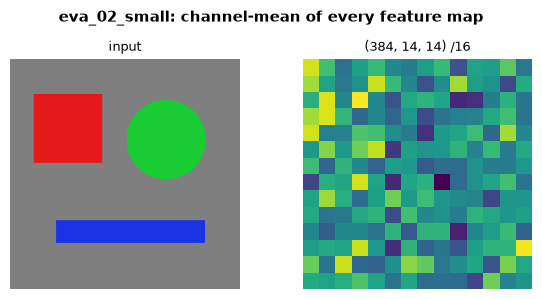

In [20]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [21]:
import sys
import numpy as np
import matplotlib.pyplot as plt

Parameters:   21,569,664
Embed dim:    384
Patch size:   16
RoPE cos buf: torch.Size([196, 64])

pooled_output:  torch.Size([1, 384])
patch_tokens:   torch.Size([1, 196, 384])
feature_maps:   torch.Size([1, 384, 14, 14])


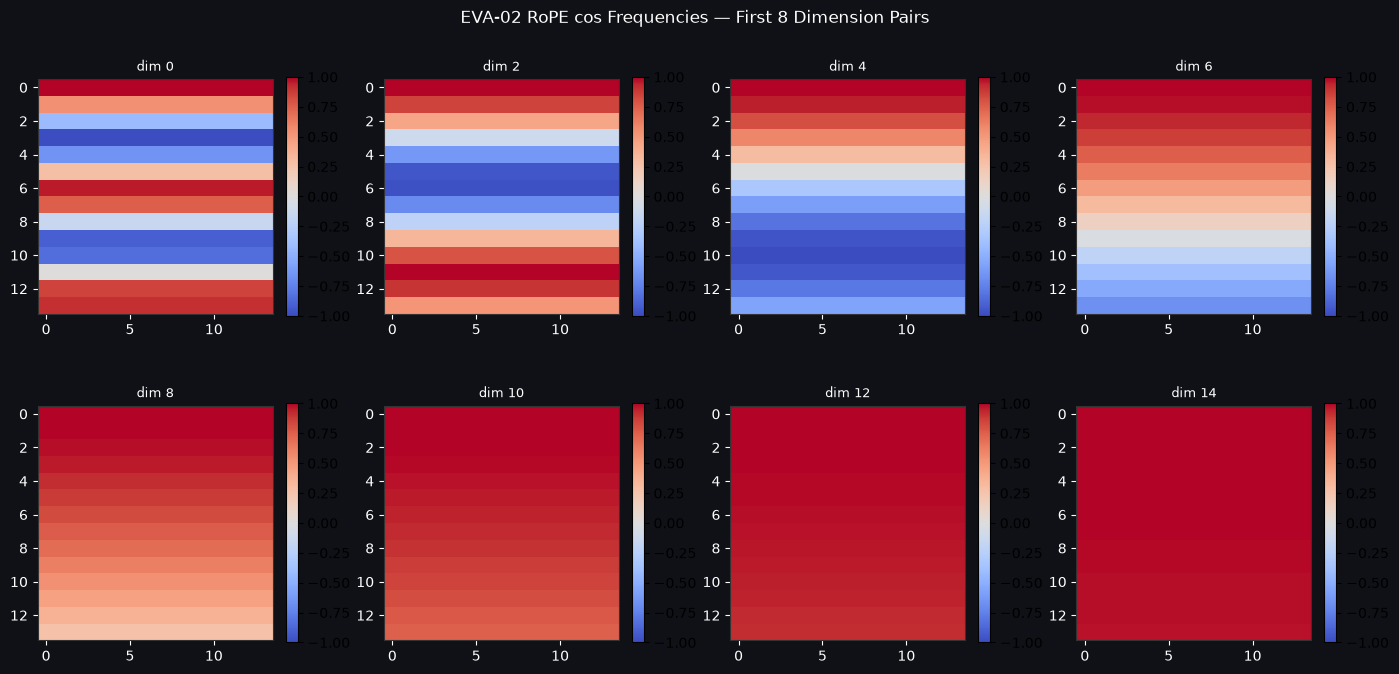

Low-freq dims (left): gradual spatial variation = global position
High-freq dims (right): rapid variation = fine-grained position discrimination


In [22]:
import sys

import torch
import numpy as np
import matplotlib.pyplot as plt

backbone = build_vision_backbone('eva_02_small', img_size=224)
backbone.eval()
print(f'Parameters:   {backbone.num_parameters():,}')
print(f'Embed dim:    {backbone.embed_dim}')
print(f'Patch size:   {backbone.patch_size}')
print(f'RoPE cos buf: {backbone.rope_cos.shape}')  # [N, head_dim]

x = torch.randn(1, 3, 224, 224)
with torch.no_grad():
    out = backbone(x)

print(f'\npooled_output:  {out.pooled_output.shape}')   # [1, 384]
print(f'patch_tokens:   {out.patch_tokens.shape}')      # [1, 196, 384]
print(f'feature_maps:   {out.feature_maps[0].shape}')   # [1, 384, 14, 14]

# Visualise RoPE frequency patterns
cos_freqs = backbone.rope_cos.numpy()  # [N, head_dim]
N = cos_freqs.shape[0]
G = int(N**0.5)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.patch.set_facecolor('#0f1117')
fig.suptitle('EVA-02 RoPE cos Frequencies — First 8 Dimension Pairs', color='white', fontsize=12)

for i, ax in enumerate(axes.flat):
    ax.set_facecolor('#0f1117')
    if i < 8:
        freq_map = cos_freqs[:, i*2].reshape(G, G)
        im = ax.imshow(freq_map, cmap='coolwarm', interpolation='nearest', vmin=-1, vmax=1)
        ax.set_title(f'dim {i*2}', color='white', fontsize=9)
        plt.colorbar(im, ax=ax, fraction=0.046)
    ax.tick_params(colors='white')
    for sp in ax.spines.values():
        sp.set_edgecolor('#333')

plt.tight_layout()

plt.show()
print('Low-freq dims (left): gradual spatial variation = global position')
print('High-freq dims (right): rapid variation = fine-grained position discrimination')

## References

### Primary
1. Y. Fang et al., "EVA-02: A Visual Representation Powerhouse Reconstructed from EVA," *arXiv:2303.11331*, 2023. [arXiv:2303.11331](https://arxiv.org/abs/2303.11331)
2. Y. Fang et al., "EVA: Exploring the Limits of Masked Visual Representation Learning at Scale," *CVPR 2023*. [arXiv:2211.07636](https://arxiv.org/abs/2211.07636) — EVA v1

### Related Works
3. N. Shazeer, "GLU Variants Improve Transformer," *arXiv:2002.05202*, 2020. [arXiv:2002.05202](https://arxiv.org/abs/2002.05202) — SwiGLU
4. J. Su et al., "RoFormer: Enhanced Transformer with Rotary Position Embedding," *Neurocomputing*, 2024. [arXiv:2104.09864](https://arxiv.org/abs/2104.09864) — RoPE
5. A. Henry et al., "Query-Key Normalization for Transformers," *EMNLP Findings 2020*. [arXiv:2010.04245](https://arxiv.org/abs/2010.04245) — QK Normalization
6. A. Radford et al., "Learning Transferable Visual Models From Natural Language Supervision," *ICML 2021*. [arXiv:2103.00020](https://arxiv.org/abs/2103.00020) — CLIP (EVA-02 trains with CLIP alignment)
7. A. Dosovitskiy et al., "An Image is Worth 16×16 Words," *ICLR 2021*. [arXiv:2010.11929](https://arxiv.org/abs/2010.11929)